In [1]:
from networkx.algorithms.community.louvain import louvain_communities
%load_ext autoreload
%autoreload 1

In [2]:
import networkx as nx

from actors_graph import ActorsGraph

actors_graph = ActorsGraph("../resources/movie/data/casts.html")
actors_graph.build()
nx.write_gexf(actors_graph.g, "../results/actor_graph.gexf")

In [4]:
stats = actors_graph.stats()
print(stats)

{'nodes_count': 15848, 'edges_count': 143972, 'density': 0.0011465328776337916, 'clustering_coefficient': 0.7172466780239253, 'bridges': [('ray milland', 'claire griswold'), ('sophia loren', 'luca defillipo'), ('richard boone', 'joan vanark'), ('harvey keitel', 'zina bethune'), ('marcello mastroianni', 'anouk grinberg'), ('michael riley', 'stephen rappaport'), ('albert brooks', 'super dave osborne'), ('charles grodin', 'marlo thomas'), ('rip torn', 'kevin conway'), ('seymour hicks', 'ellaline teriss'), ('richard roundtree', 'ed kovens'), ('duke howard', 'burt brinckerhoff'), ('marshall thompson', 'marla landi'), ('ethan hawke', 'julie delpie'), ('robert deniro', 'lenny bruce'), ('emilio estevez', 'phil brock'), ('anouk aimee', 'ives montand'), ('claude noiller', 'valentine tessier'), ('jean gabin', 'josephine baker'), ('lyda bonelli', 'mario bonnard'), ('christopher dienstag', 'monica caldwell'), ('kim basinger', 'lisa croisette'), ('michael douglas', 'marjorie griffiths'), ('glenn clo

## Bridges with degree higher than one 1

In [29]:
print("Bridges count: ", len(stats["bridges"]))
bridges = [
    (a, b) for (a, b) in stats["bridges"]
    if actors_graph.g.degree(a) > 1 and actors_graph.g.degree(b) > 1
]
bridges

Bridges count:  438


[('giacomo rossistuart', 'vincent price'),
 ('karen black', 'michael emil'),
 ('chuck connors', 'rosel zech'),
 ('john hargreaves', 'bryan brown'),
 ('helmut berger', 'marisa mell'),
 ('john belushi', 'blair brown'),
 ('francisco rabal', 'silvia pinal')]

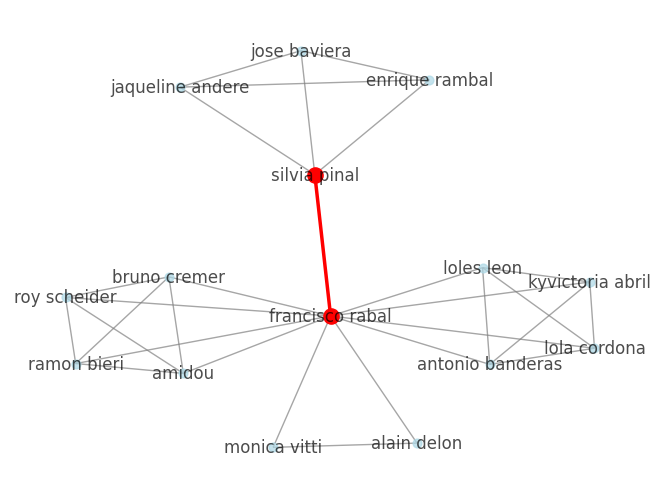

In [28]:
import networkx as nx
from matplotlib import pyplot as plt

u, v = ('francisco rabal', 'silvia pinal')
# nodes_u = nx.single_source_shortest_path_length(actors_graph.g, u, cutoff=2).keys()
nodes_u = nx.neighbors(actors_graph.g, u)
nodes_v = nx.neighbors(actors_graph.g, v)
# nodes_v = nx.single_source_shortest_path_length(actors_graph.g, v, cutoff=2).keys()
nodes = set(nodes_u) | set(nodes_v)

subG = actors_graph.g.subgraph(nodes).copy()
pos = nx.kamada_kawai_layout(subG)
scale = 3
pos = {k: (x * scale, y * scale) for k, (x, y) in pos.items()}

# base graph
nx.draw(
    subG,
    pos,
    node_size=40,
    node_color="lightblue",
    edge_color="gray",
    with_labels=True,
    alpha=0.7
)

# highlight nodes
nx.draw_networkx_nodes(
    subG,
    pos,
    nodelist=[u, v],
    node_color="red",
    node_size=120
)

# highlight edge
nx.draw_networkx_edges(
    subG,
    pos,
    edgelist=[(u, v)],
    edge_color="red",
    width=2.5
)
plt.show()

## Local bridges with degree > 1

In [ ]:
bridges = [
    (a, b) for (a, b, _) in stats["local_bridges"]
    if actors_graph.g.degree(a) > 1 and actors_graph.g.degree(b) > 1
]
bridges

In [ ]:
import networkx as nx
from matplotlib import pyplot as plt

u, v = ('alfie bass', 'david kosoff')
# nodes_u = nx.single_source_shortest_path_length(actors_graph.g, u, cutoff=2).keys()
nodes_u = nx.neighbors(actors_graph.g, u)
nodes_v = nx.neighbors(actors_graph.g, v)
# nodes_v = nx.single_source_shortest_path_length(actors_graph.g, v, cutoff=2).keys()
nodes = set(nodes_u) | set(nodes_v)

subG = actors_graph.g.subgraph(nodes).copy()
pos = nx.kamada_kawai_layout(subG)
scale = 3  # try 2–5
pos = {k: (x * scale, y * scale) for k, (x, y) in pos.items()}

# base graph
nx.draw(
    subG,
    pos,
    node_size=40,
    node_color="lightblue",
    edge_color="gray",
    with_labels=True,
    alpha=0.7
)

# highlight nodes
nx.draw_networkx_nodes(
    subG,
    pos,
    nodelist=[u, v],
    node_color="red",
    node_size=120
)

# highlight edge
nx.draw_networkx_edges(
    subG,
    pos,
    edgelist=[(u, v)],
    edge_color="red",
    width=2.5
)
plt.show()

## Degree distribution

Top 5 by degree: [('humphrey bogart', 412), ('gary cooper', 358), ('james stewart', 357), ('john gielgud', 356), ('john carradine', 354)]
0 413 1


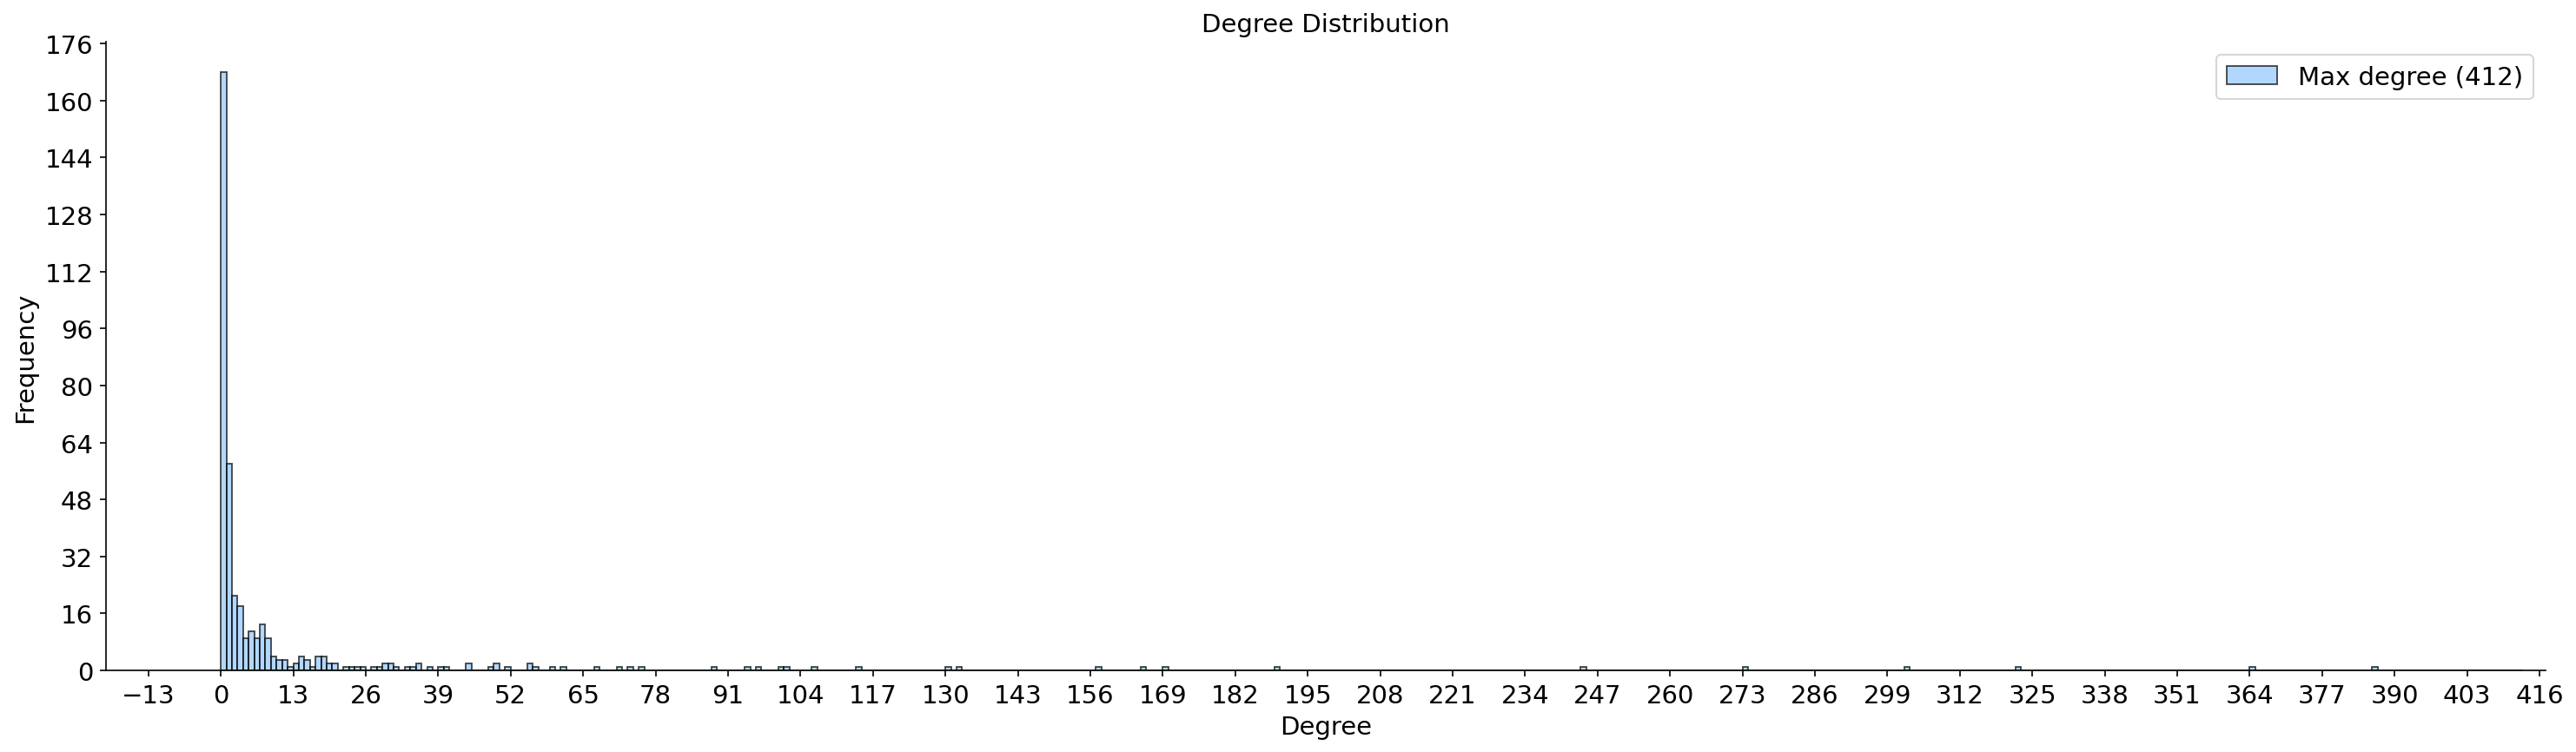

In [26]:
import importlib
import plotter
import pandas as pd

importlib.reload(plotter)

from plotter import Plotter
top_by_degree = sorted(actors_graph.g.degree, key=lambda x: x[1], reverse=True)[:5]
print("Top 5 by degree:", top_by_degree)
Plotter().plot_histogram_bin_count(
    sequence=stats["degree_histogram"],
    bins_count=len(stats["degree_histogram"]),
    log_y_scale=False,
    title="Degree Distribution",
    x_label="Degree",
    y_label="Frequency",
    label=f"Max degree ({top_by_degree[0][1]})",
    x_majors=30
)

DegreeView({'leslie howard': 138, 'wendy hiller': 136, 'wilfrid lawson': 50, 'scott sunderland': 13, 'marie lohr': 61, 'david tree': 21, 'esme percy': 28, 'everley gregg': 13, 'jean cadell': 43, 'ray milland': 231, 'ellen drew': 43, 'guy middleton': 29, 'ronald culver': 3, 'margaret lockwood': 72, 'derek farr': 24, 'marjorie fielding': 8, 'athene seyler': 30, 'peggy ashcroft': 39, 'margaretta scott': 18, 'bernard miles': 58, 'michael redgrave': 126, 'michael denison': 7, 'edith evans': 56, 'margaret rurtherford': 7, 'jaen greenwood': 7, 'miles malleson': 93, 'doroty tutin': 7, 'walter hudd': 7, 'dirk bogarde': 91, 'olivia dehavilland': 115, 'paul massie': 8, 'wilfrid hyde white': 71, 'robert morley': 211, 'anthony dawson': 43, 'richard wattis': 41, 'martin miller': 53, 'millicent martin': 16, 'peter sellers': 183, 'sophia loren': 102, 'alastair sim': 44, 'vittorio desics': 6, 'dennis price': 58, 'gary raymond': 33, 'alfie bass': 27, 'richard burton': 185, 'elizabeth taylor': 232, 'magg

## Components

In [5]:
components_stats = actors_graph.component_stats()

In [6]:
components_stats

{'num_components': 731,
 'largest_size': 14062,
 'largest_ratio': 0.8873043917213529,
 'singletons': 322,
 'below_10_nodes': 400,
 'below_100_nodes': 8,
 'above_100_nodes': 0}

In [7]:
components = nx.connected_components(actors_graph.g)

In [8]:
singletons = [
    comp for comp in components if len(comp) == 1
]

In [9]:
singletons[0]

{'thais galizky'}

## Centralities

In [65]:
degree_output = nx.degree_centrality(actors_graph.g)
top_by_degree = sorted(degree_output.items(), key=lambda item: item[1], reverse=True)[:10]
top_by_degree

[('humphrey bogart', 0.02599861172461665),
 ('gary cooper', 0.022591026692749417),
 ('james stewart', 0.022527923266233357),
 ('john gielgud', 0.022464819839717296),
 ('john carradine', 0.02233861298668518),
 ('peter lorre', 0.0218337855745567),
 ('c.aubrey smith', 0.020571717044235504),
 ('henry fonda', 0.019688269073010665),
 ('burt lancaster', 0.019057234807850067),
 ('david niven', 0.018931027954817947)]

In [48]:
closeness_output = nx.closeness_centrality(actors_graph.g)
top_by_closeness = sorted(closeness_output.items(), key=lambda item: item[1], reverse=True)[:10]
top_by_closeness

[('charlton heston', 0.3444204686806322),
 ('john gielgud', 0.3437277752290057),
 ('burt lancaster', 0.3431038983991206),
 ('henry fonda', 0.34006451857520775),
 ('john carradine', 0.33975891335985464),
 ('david niven', 0.3383675162043616),
 ('james stewart', 0.3374158118100179),
 ('robert mitchum', 0.33645129867556284),
 ('robert deniro', 0.33513181093497424),
 ('laurence olivier', 0.33512280903293723)]

In [83]:
for id, score in top_by_degree:
    print(id, score, actors_graph.g.degree[id])

c.aubrey smith 0.10485028886498275 326
john carradine 0.09881481860018791 354
peter lorre 0.09295870749885816 346
james stewart 0.09258502168958771 357
john gielgud 0.09131177574071166 356
gary cooper 0.09023493963125748 358
david niven 0.08839774672650973 300
basil rathbone 0.08822845125407812 293
andy devine 0.08588618791107584 243
henry fonda 0.08437356735112676 312


In [61]:
betweenness_output = nx.betweenness_centrality(actors_graph.g)
top_by_betweenness = sorted(betweenness_output.items(), key=lambda item: item[1], reverse=True)[:10]
top_by_betweenness

[('robert deniro', 0.011315137095846394),
 ('john carradine', 0.01086691513863796),
 ('vincent price', 0.010764103931666874),
 ('humphrey bogart', 0.010686893357448995),
 ('burt lancaster', 0.01057764571087529),
 ('gene hackman', 0.009937017131140062),
 ('john gielgud', 0.009453148331635056),
 ('charlton heston', 0.009323707105524007),
 ('jack nicholson', 0.00887439303377209),
 ('james stewart', 0.008032388751603566)]

In [63]:
eigenvector_output = nx.eigenvector_centrality(actors_graph.g)
top_by_eigenvector = sorted(eigenvector_output.items(), key=lambda item: item[1], reverse=True)[:10]
top_by_eigenvector


[('c.aubrey smith', 0.10485028886498275),
 ('john carradine', 0.09881481860018791),
 ('peter lorre', 0.09295870749885816),
 ('james stewart', 0.09258502168958771),
 ('john gielgud', 0.09131177574071166),
 ('gary cooper', 0.09023493963125748),
 ('david niven', 0.08839774672650973),
 ('basil rathbone', 0.08822845125407812),
 ('andy devine', 0.08588618791107584),
 ('henry fonda', 0.08437356735112676)]

In [84]:
for id, score in top_by_eigenvector:
    print(id, score, actors_graph.g.degree[id])

c.aubrey smith 0.10485028886498275 326
john carradine 0.09881481860018791 354
peter lorre 0.09295870749885816 346
james stewart 0.09258502168958771 357
john gielgud 0.09131177574071166 356
gary cooper 0.09023493963125748 358
david niven 0.08839774672650973 300
basil rathbone 0.08822845125407812 293
andy devine 0.08588618791107584 243
henry fonda 0.08437356735112676 312


In [75]:
tops = [top_by_degree, top_by_betweenness, top_by_closeness, top_by_eigenvector]
top_ids = []
for top in tops:
    top_ids.append(
        set([entry[0] for entry in top])
    )

top_intersection = top_ids[0]
for top in top_ids[1:]:
    top_intersection = top_intersection & top
top_intersection

{'james stewart', 'john carradine', 'john gielgud'}

In [76]:
top_ids[1] & top_ids[2]

{'burt lancaster',
 'charlton heston',
 'james stewart',
 'john carradine',
 'john gielgud',
 'robert deniro'}

## Clusters/Communities

In [133]:
communities = nx.community.louvain_communities(actors_graph.g)

print("Communities present", len(communities))

Communities present 784


In [134]:
print("Singleton communities", len([comm for comm in communities if len(comm) == 1]))
print("Above 10 nodes", len([comm for comm in communities if len(comm) > 10]))
print("Above 100, below 1000 nodes", len([comm for comm in communities if len(comm) > 100 and len(comm) <1000]))
print("Above 1000 nodes", len([comm for comm in communities if len(comm) > 1000]))

Singleton communities 322
Above 10 nodes 35
Above 100, below 1000 nodes 12
Above 1000 nodes 4


## Kevin Bacon number

In [4]:
from numpy import inf

node_distances = []
for node in actors_graph.g.nodes:
    try:
        dist = nx.shortest_path_length(actors_graph.g, source=node, target="kevin bacon")
    except:
        dist = inf
    node_distances.append({
        "node": node,
        "distance": dist
    })

In [12]:
import numpy as np
import pandas as pd
df = pd.DataFrame(node_distances, columns=["node", "distance"])
df = df[df["distance"] != np.inf]

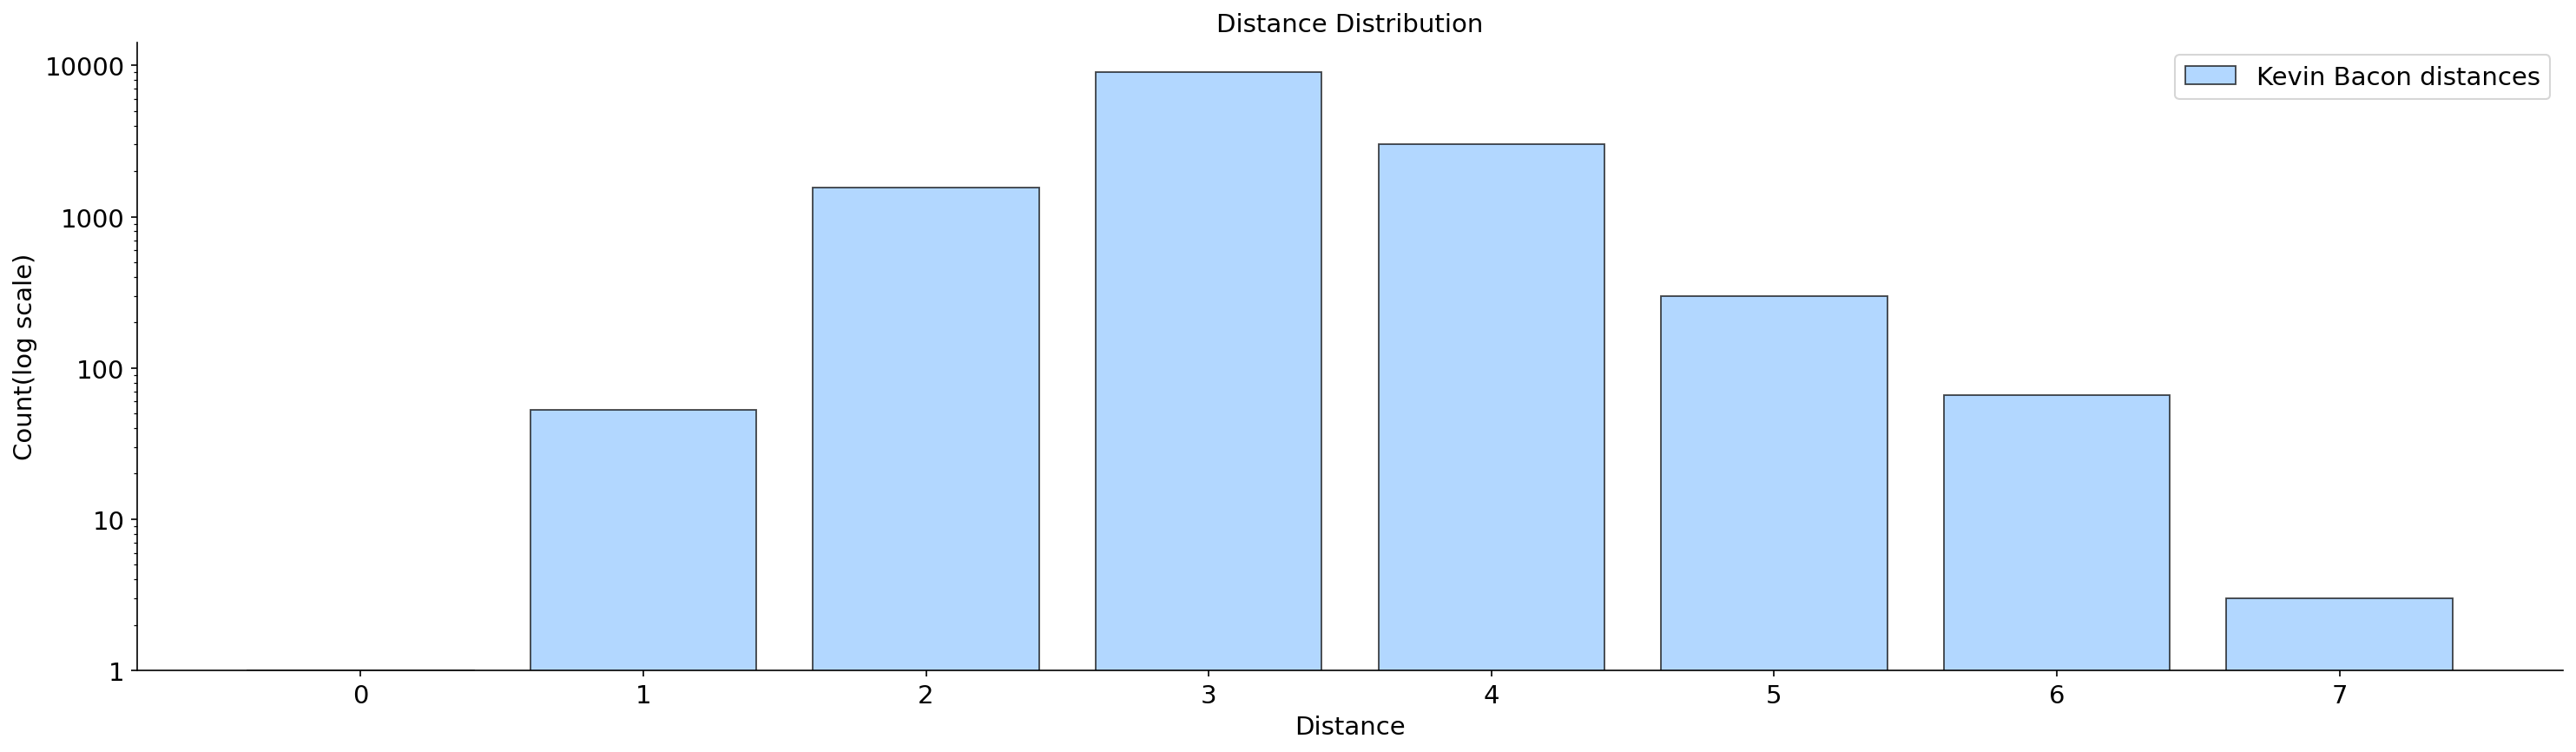

In [13]:
import importlib
from plotter import Plotter
importlib.reload(plotter)

sequence = df["distance"].to_numpy()
Plotter().plot_distance_distribution(
    sequence,
    label="Kevin Bacon distances",
    log_y_scale=True
)

In [15]:
print("Nodes with maximum distance")
df[df["distance"] == df["distance"].max()]

Nodes with maximum distance


,node,distance
14448,haren chatterjee,7.0
14449,haradhan banerjee,7.0
14873,kazuo hasegawa,7.0
